In [1]:
from ntrfc.turbo.cascade_case.domain import CascadeWindTunnelDomain2D
from ntrfc.turbo.cascade_case.utils.domain_utils import Blade2D,CascadeWindTunnelDomain2DParameters
from ntrfc.turbo.gmsh.windtunnel_cascade import create_mesh, MeshConfig
import os
import pyvista as pv
import numpy as np
from ntrfc.turbo.airfoil_generators.naca_airfoil_creator import naca

In [2]:
pv.set_jupyter_backend("static")

if os.getenv('DISPLAY') is None:
    pv.start_xvfb()  # Start X virtual framebuffer (Xvfb)

In [3]:


xs,ys = naca("6510",256)
points = pv.PolyData(np.stack([xs,ys,np.zeros(len(xs))]).T*0.06)

In [4]:

gwkconfig = CascadeWindTunnelDomain2DParameters(gamma=6,
                                                gittervor=0.03,
                                                pitch=0.06,
                                                gitternach=0.04,
                                                zulauf=0.8,
                                                tailbeta=0,
                                                nblades=5
                                                )

In [5]:

meshconfig = MeshConfig(lc_high=0.00036,
                        lc_low=0.0036,
                        bl_size=1.8e-6,
                        progression_le=0.01,
                        progression_te=0.01,
                        bl_thickness= 0.0014,
                        )


working with pv.PolyData, dataarrays can be used for postprocessing


/home/many/miniconda3/envs/NTRfC/lib/python3.10/site-packages/pyvista/core/filters/poly_data.py:2942: PyVistaFutureWarning: The default value of the ``capping`` keyword argument will change in a future version to ``True`` to match the behavior of VTK. We recommend passing the keyword explicitly to prevent future surprises.
  warnings.warn(


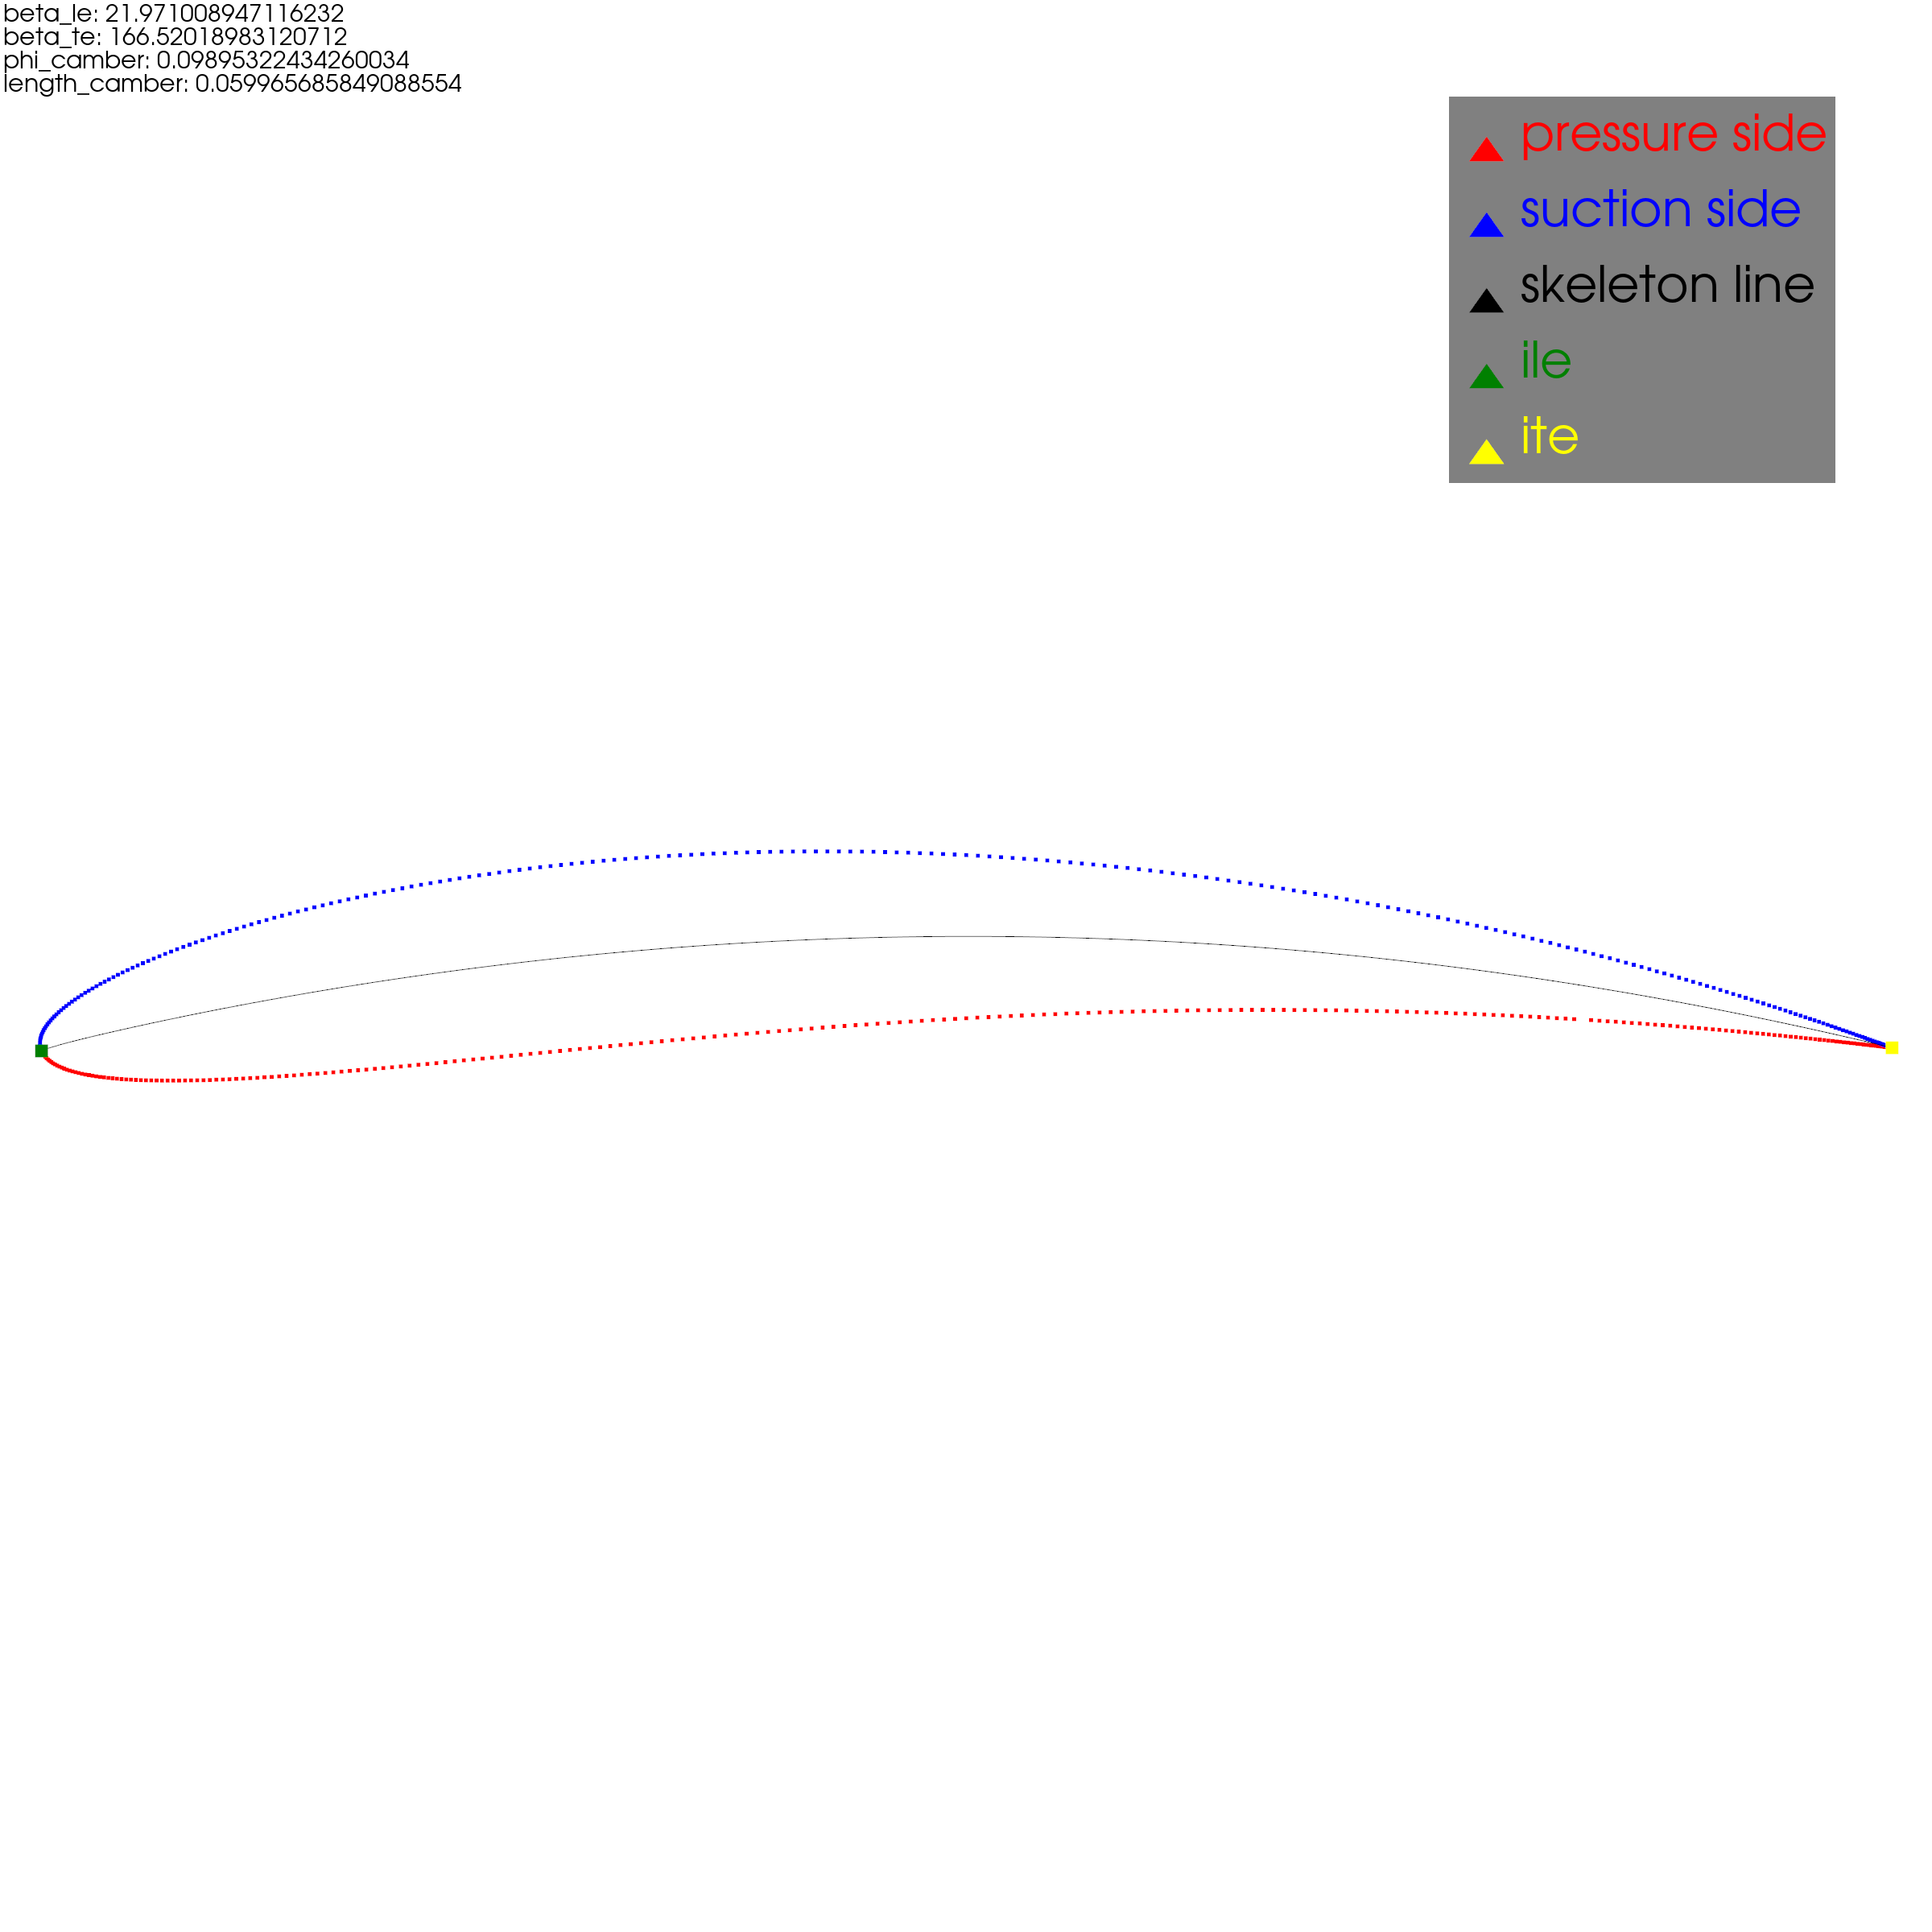

In [6]:
blade = Blade2D(points)
blade.compute_all_frompoints()

fig = blade.plot()

In [7]:
domain2d = CascadeWindTunnelDomain2D()
domain2d.generate_from_cascade_parameters(gwkconfig,blade)
fig = domain2d.plot_domain()

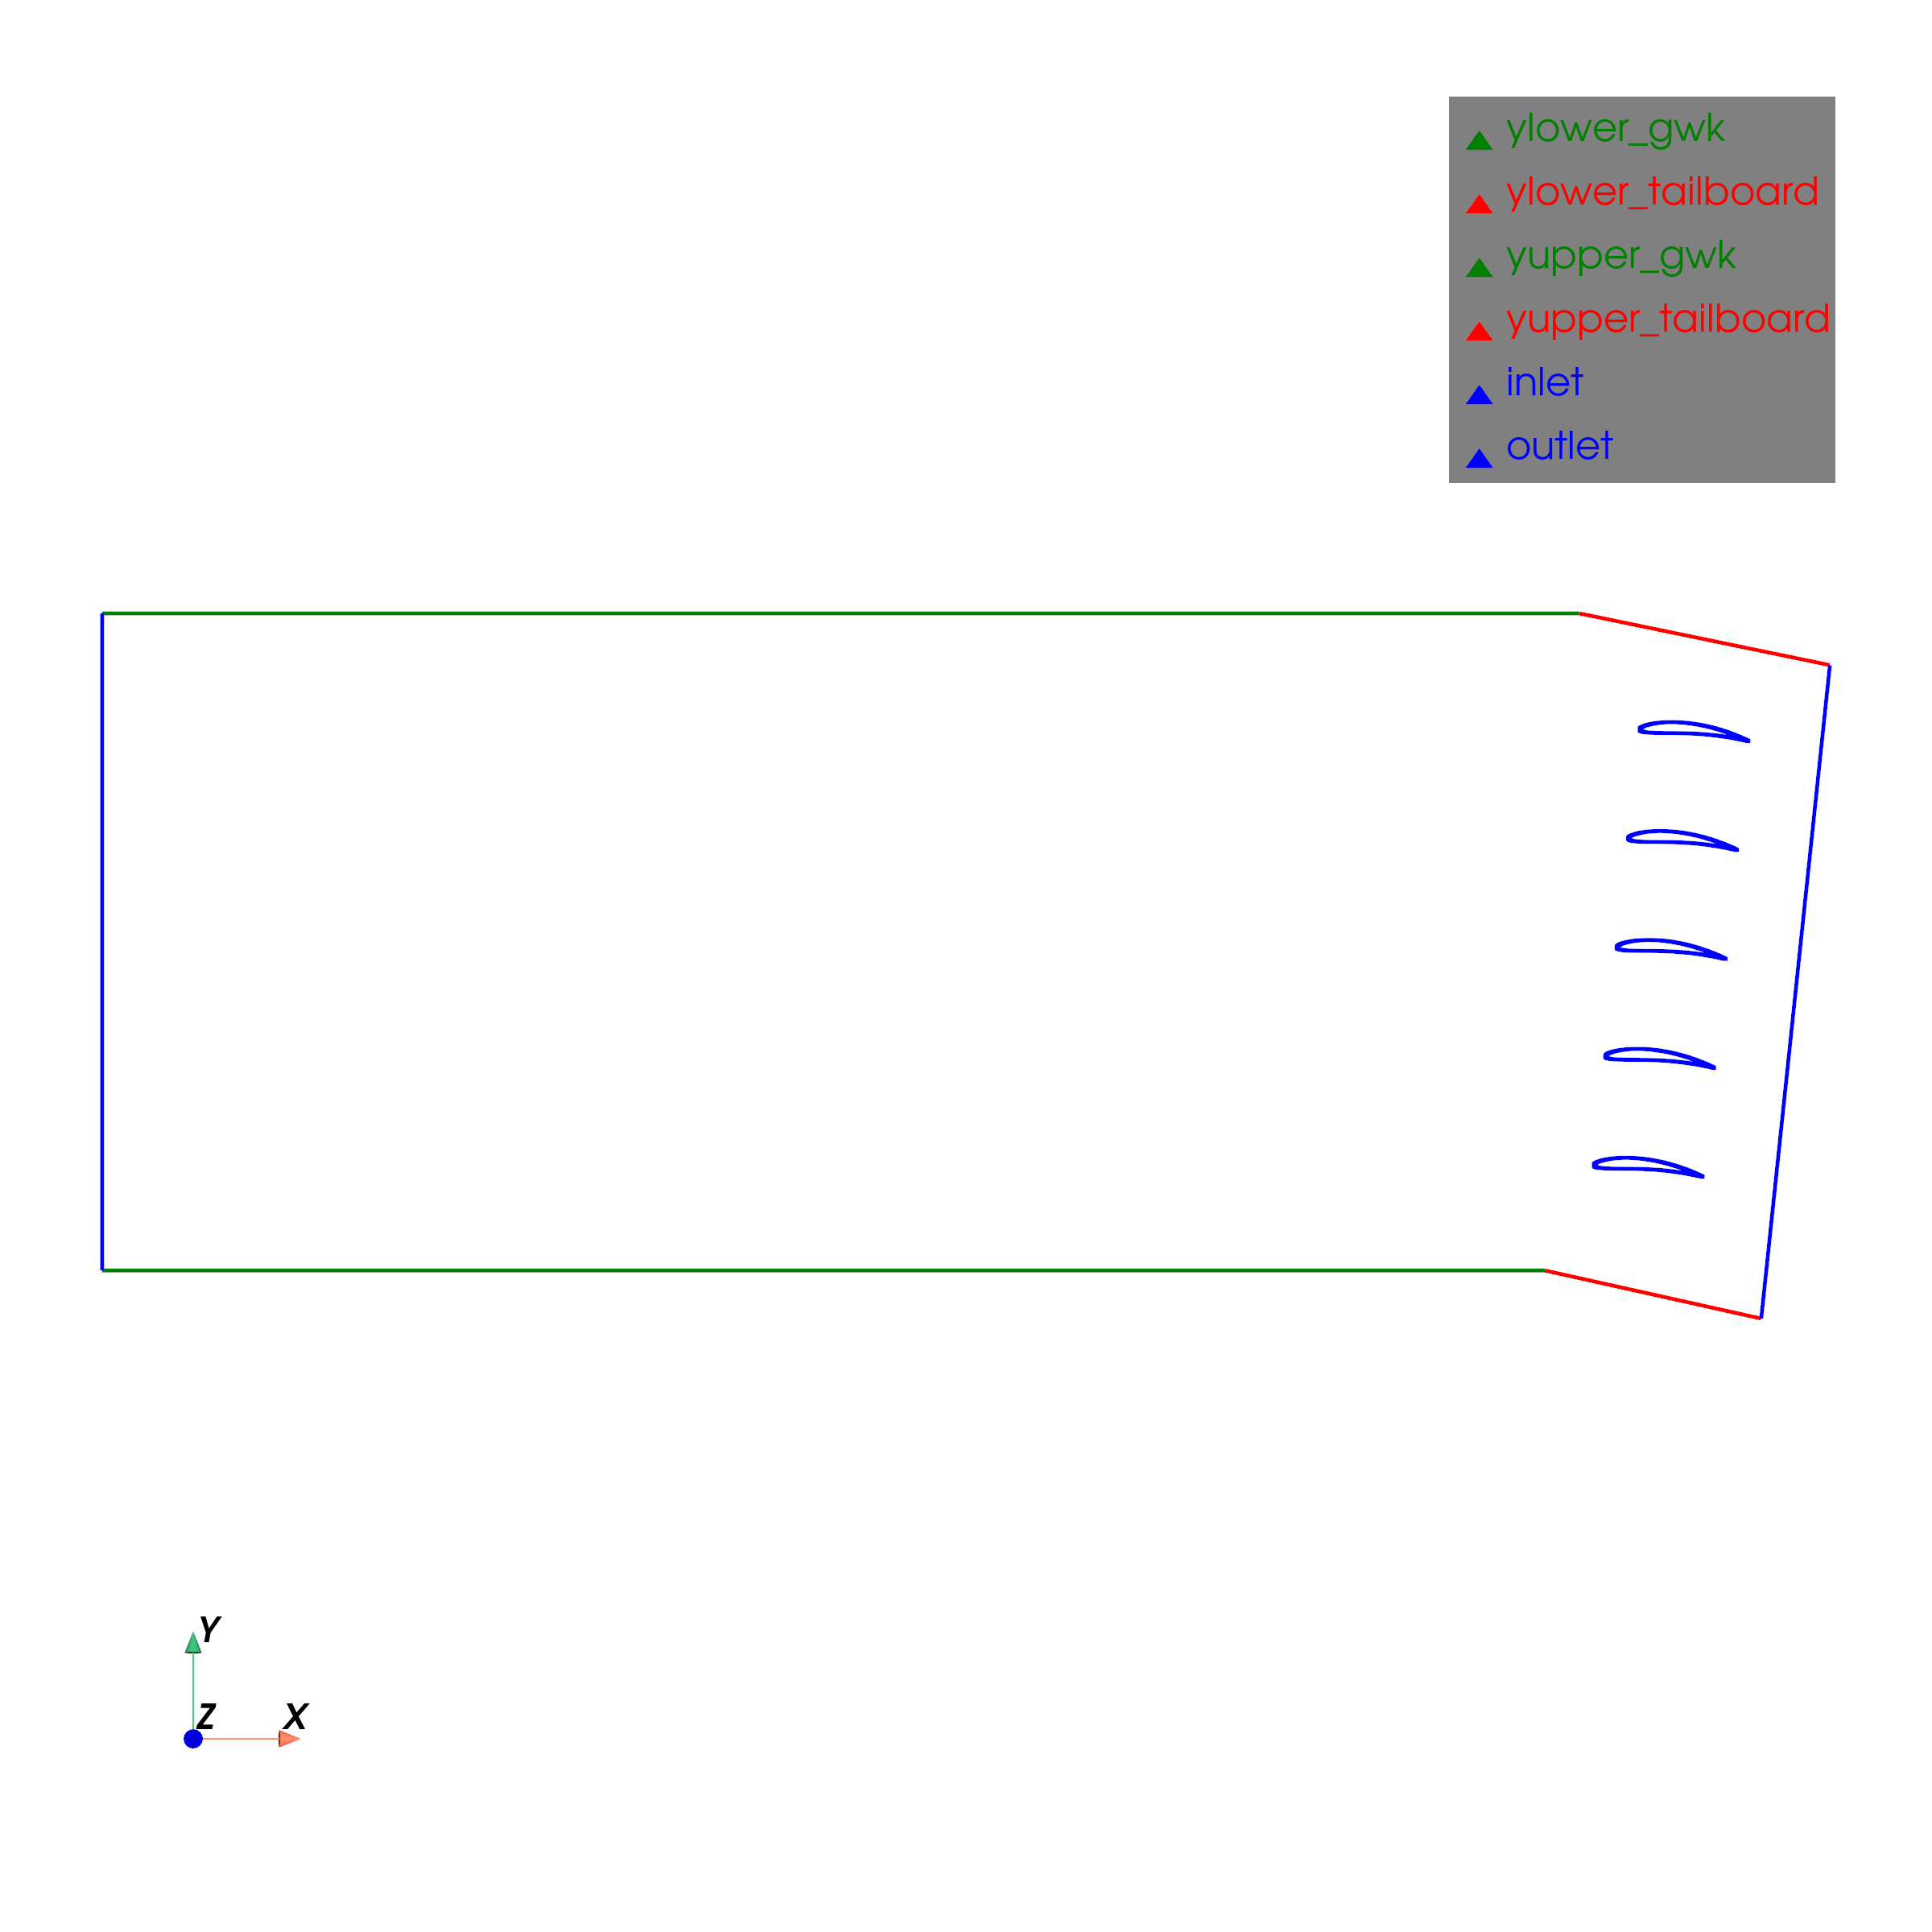

In [8]:

from IPython.display import Image

Image(fig, width=400, height=400)

In [9]:
create_mesh(domain2d, gwkconfig,meshconfig, blade, "test.msh")


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 10%] Meshing curve 3 (Line)
Info    : [ 10%] Meshing curve 4 (Line)
Info    : [ 10%] Meshing curve 5 (Line)
Info    : [ 10%] Meshing curve 6 (Line)
Info    : [ 10%] Meshing curve 7 (Line)
Info    : [ 10%] Meshing curve 8 (Line)
Info    : [ 10%] Meshing curve 9 (Line)
Info    : [ 10%] Meshing curve 10 (Line)
Info    : [ 20%] Meshing curve 11 (Line)
Info    : [ 20%] Meshing curve 12 (BSpline)
Info    : [ 20%] Meshing curve 13 (BSpline)
Info    : [ 20%] Meshing curve 14 (BSpline)
Info    : [ 20%] Meshing curve 15 (BSpline)
Info    : [ 20%] Meshing curve 16 (BSpline)
Info    : [ 20%] Meshing curve 17 (BSpline)
Info    : [ 20%] Meshing curve 18 (BSpline)
Info    : [ 20%] Meshing curve 19 (BSpline)
Info    : [ 30%] Meshing curve 20 (BSpline)
Info    : [ 30%] Meshing curve 21 (BSpline)
Info    : [ 30%] Meshing curve 22 (BSpline)
Info    : [ 30%] Meshing curve 23 (BSpline)
Info  

Info    : [  0%] Blossom recombination completed (Wall 23.7804s, CPU 23.8008s): 336405 quads, 56779 triangles, 0 invalid quads, 35 quads with Q < 0.1, avg Q = 0.879605, min Q = 0.0475029
Info    : [ 10%] Meshing surface 2 (Plane, Frontal-Delaunay)


Info    : [ 10%] Blossom recombination completed (Wall 0.993826s, CPU 0.996307s): 20866 quads, 5811 triangles, 0 invalid quads, 0 quads with Q < 0.1, avg Q = 0.785311, min Q = 0.383913
Info    : [ 10%] Meshing surface 3 (Extruded)
Info    : [ 10%] Meshing surface 4 (Extruded)
Info    : [ 20%] Meshing surface 5 (Extruded)
Info    : [ 20%] Meshing surface 6 (Extruded)
Info    : [ 20%] Meshing surface 7 (Extruded)
Info    : [ 30%] Meshing surface 8 (Extruded)
Info    : [ 30%] Meshing surface 9 (Extruded)
Info    : [ 30%] Meshing surface 10 (Extruded)
Info    : [ 30%] Meshing surface 11 (Extruded)
Info    : [ 40%] Meshing surface 12 (Extruded)
Info    : [ 40%] Meshing surface 13 (Extruded)
Info    : [ 40%] Meshing surface 14 (Extruded)
Info    : [ 50%] Meshing surface 15 (Extruded)
Info    : [ 50%] Meshing surface 16 (Extruded)
Info    : [ 50%] Meshing surface 17 (Extruded)
Info    : [ 50%] Meshing surface 18 (Extruded)
Info    : [ 60%] Meshing surface 19 (Extruded)
Info    : [ 60%] Meshin

Info    : Writing 'test.msh'...
Info    : Done writing 'test.msh'


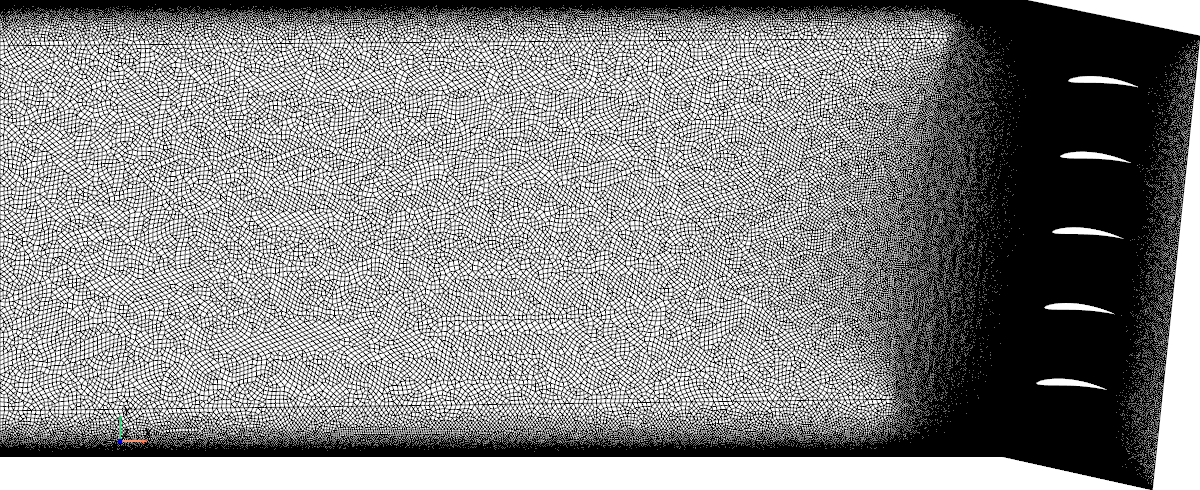

In [10]:
from ntrfc.filehandling.mesh import load_mesh
import pyvista as pv
mesh = load_mesh("test.msh")

p = pv.Plotter(window_size=[1200,600])
p.add_mesh(mesh.extract_feature_edges(),color="black")
p.view_xy()
p.add_axes()
p.camera.zoom("tight")
p.show()
